# P16 — Vias por cluster (GSEA: Reactome, KEGG e Hallmark), com foco em Treg × T efetora

**Perguntas.** (1) Que vias caracterizam cada tipo de célula T CD4⁺ do atlas L2, comparado com os
demais? (2) Principalmente: que vias separam as Treg das T efetoras?

**Ponto de partida.** O objeto final do P13 (`dataReseq/analises_previas/P13_objeto_final/reseq_final.h5ad`), as
mesmas 30.002 células CD4⁺ com rótulo do atlas usadas no P15.

**Método: o mesmo do projeto espacial** (`/mnt/SATA/analiseR/GSEA.rmd`, explicado em
`GSEA_workflow_metodos.md` e `GSEA_alteracoes.md`). O código R é a cópia dos chunks do Rmd, na
mesma ordem ([functions/gsea_vias.R](../../functions/gsea_vias.R)); as alterações estão marcadas com
`[P16]`. Em resumo: marcadores do `FindAllMarkers` → score `avg_log2FC × −log10(p_val_adj)` (p = 0
trocado pelo menor p não nulo) → GSEA pré-ranqueado por cluster (`gsePathway`, `gseKEGG`, `GSEA`
com a coleção H do MSigDB), BH dentro de cada cluster e base, corte p.adj ≤ 0,05 → filtro de
redundância (Jaccard < 5 % no core enrichment; não no Hallmark) → 5 vias marcadoras por cluster,
sem repetir → painel por cluster, plot combinado via × cluster e comparação direta de clusters.

**Três execuções do mesmo script:**

| execução | células | clusters | comparação direta |
| --- | --- | --- | --- |
| `L2` | 30.002 CD4⁺ | os 18 tipos do atlas L2 | TregEff × TemTh1 |
| `treg_teff_estrita` | Treg + Teff estrita | Treg (TregNaive, TregAct, TregEff) × Teff (TemTh1, TemTh1pre, TemTh117, TemTph, TemraTh1, TcmTh0Act) | Treg × Teff |
| `treg_teff_ampla` | Treg + Teff ampla | Treg × Teff (toda CD4⁺ de memória: Tcm\*, Tem\*, Temra) | Treg × Teff |

As definições de Treg e Teff são as do atlas no P14. A estrita é a principal; a ampla é a
sensibilidade. Com dois grupos, o "cluster contra o resto" do FindAllMarkers é o contraste
Treg × Teff: o ranking da Teff é o da Treg com o sinal trocado, e as duas colunas das figuras são
o mesmo teste visto dos dois lados.

## Adaptação: o que mudou e por quê

1. **FindAllMarkers.** O espacial lia uma tabela pronta (`FindAllMarkers_results.rds`), sem os
   parâmetros no script. Aqui ele roda no R com o **ranking completo de genes, sem cortes**
   (`logfc.threshold = 0`, `min.pct = 0`, `return.thresh = Inf`), escolha do usuário. Os padrões do
   Seurat 5 cortariam o ranking nos genes com p < 0,01. O Wilcoxon usa o `presto`, que dá os mesmos
   p-valores do `wilcox.test` (aproximação normal, correção de empates e de continuidade).
1b. **Score com o p bruto.** O score do espacial usa o `p_val_adj`, que no Seurat é Bonferroni
   sobre ~26 mil genes. Com o ranking completo, ~80 % dos genes ficam com `p_val_adj` = 1 e score
   0; o peso se concentra em poucas dezenas de genes, e conjuntos aleatórios também dão ES ≈ ±1.
   O GSEA perde o poder: na TregEff, a via MHC classe II tem p.adj 0,76 com o `p_val_adj` e 0,004
   com o `p_val`. O score passa a ser `avg_log2FC × −log10(p_val)`, com o mesmo piso para p = 0; a
   correção múltipla continua no BH do GSEA. Nenhum gene sai do ranking.
2. **Assay.** `RNA`: contagens SoupX com `LogNormalize` (10 mil por célula), a mesma normalização
   do `X` do objeto final. Não há SCT neste projeto, e a matriz do ComBat não serve para expressão
   diferencial.
3. **Cluster.** `atlas_L2` (no espacial, `leiden_0_8`), e as duas execuções Treg × Teff.
4. **Ordem dos clusters.** A seleção das vias marcadoras é gulosa: uma via compartilhada fica com o
   primeiro cluster que a escolhe. No espacial a ordem era a numérica; aqui é a do atlas
   (Tnaive → Tcm → Tem → Temra → Treg), também no Reactome.
5. **Saída.** Figuras em `resultsReseq/figures/analises_previas/P16_gsea_vias/<execução>/` e tabelas em
   `resultsReseq/tables/analises_previas/P16_gsea_vias/<execução>/`, com os nomes de arquivo do espacial.
6. **Cosmético.** Título do dotplot = nome do tipo; faixa do plot combinado sem o prefixo "C";
   tabela de marcadoras ordenada pelo nome do cluster (`as.numeric()` de um nome dá NA).

**Mantido:** o score, as três bases e suas funções, `pvalueCutoff = 1` com corte depois,
`set.seed(42)` e `seed = TRUE`, tamanhos de conjunto no padrão do clusterProfiler, o filtro de
Jaccard (5 %, com o resumo de 5/10/15 % no Reactome), a seleção e as figuras.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import time
import anndata as ad
import numpy as np
import pandas as pd
from IPython.display import Image, display

from functions import atlas, config, io, issues
from functions.droplets import run_r

NB = "analises_previas/P16_gsea_vias"
FIG = config.FIGURES / NB
TAB = config.TABLES / NB
WORK = config.HEAVY_OUT / NB
log = issues.IssueLog(NB)
pd.set_option("display.width", 220)
N_WORKERS = 8

TREG = ["TregNaive", "TregAct", "TregEff"]
TEFF_ESTRITA = ["TemTh1", "TemTh1pre", "TemTh117", "TemTph", "TemraTh1", "TcmTh0Act"]
NAIVE = ["Tnaive", "TnaiveMX1", "TnaiveAct", "TnaiveSOX4"]

## 1. Células

In [2]:
a = ad.read_h5ad(config.DATA_OUT / "analises_previas/P13_objeto_final" / "reseq_final.h5ad")
cd4 = ~a.obs["grupo"].isin(["contaminante", "baixa qualidade"])
base = (cd4 & a.obs["atlas_L2"].notna()).to_numpy()
l2 = a.obs["atlas_L2"].astype(str)
TEFF_AMPLA = [c for c in atlas.L2 if c not in TREG + NAIVE]

grupo_estrita = np.where(l2.isin(TREG), "Treg", np.where(l2.isin(TEFF_ESTRITA), "Teff", ""))
grupo_ampla = np.where(l2.isin(TREG), "Treg", np.where(l2.isin(TEFF_AMPLA), "Teff", ""))
EXECUCOES = {
    "L2": dict(mask=base, col="atlas_L2", valores=l2.to_numpy(),
               niveis=[c for c in atlas.L2 if c in set(l2[base])], comparar=["TregEff", "TemTh1"]),
    "treg_teff_estrita": dict(mask=base & (grupo_estrita != ""), col="treg_teff", valores=grupo_estrita,
                              niveis=["Treg", "Teff"], comparar=["Treg", "Teff"]),
    "treg_teff_ampla": dict(mask=base & (grupo_ampla != ""), col="treg_teff", valores=grupo_ampla,
                            niveis=["Treg", "Teff"], comparar=["Treg", "Teff"]),
}
# Sensibilidade do score no contraste principal (mesmos marcadores do FindAllMarkers):
# sinal(log2FC) × −log10(p) e só o log2FC. Ver seção 5.
for modo in ["sinal_log10p", "log2fc"]:
    EXECUCOES[f"treg_teff_estrita_{modo}"] = dict(EXECUCOES["treg_teff_estrita"], modo=modo,
                                                  marcadores_de="treg_teff_estrita")
print("Teff ampla:", ", ".join(TEFF_AMPLA))
tam = pd.DataFrame({k: pd.Series(e["valores"][e["mask"]]).value_counts() for k, e in EXECUCOES.items()})
display(tam.reindex(list(EXECUCOES["L2"]["niveis"]) + ["Treg", "Teff"]).fillna(0).astype(int))
n_lib = pd.crosstab(a.obs.loc[base, "library_id"], pd.Series(grupo_estrita[base], index=a.obs.index[base]))
display(n_lib.drop(columns="", errors="ignore").T)

Teff ampla: TcmTh0, TcmTh0Act, TcmTh17, TcmTh2, TcmTfh, TcmPHLDA3, TemTh1, TemTh117, TemTh1pre, TemTph, TemraTh1


,L2,treg_teff_estrita,treg_teff_ampla,treg_teff_estrita_sinal_log10p,treg_teff_estrita_log2fc
Tnaive,10403,0,0,0,0
TnaiveAct,2373,0,0,0,0
TnaiveMX1,2784,0,0,0,0
TnaiveSOX4,429,0,0,0,0
TcmTh0,4721,0,0,0,0
TcmTh0Act,29,0,0,0,0
TcmTh17,2250,0,0,0,0
TcmTh2,602,0,0,0,0
TcmTfh,1399,0,0,0,0
TcmPHLDA3,17,0,0,0,0


library_id,CTH92_ML,CTH92_NS,CTH94_ML,CTH94_NS,CTH97_ML,CTH97_NS,HNP44_ML,HNP44_NS,MB34_ML,MB34_NS,PB20_ML,PB20_NS,PB21_ML,PB21_NS
col_0,,,,,,,,,,,,,,
Teff,169,67,66,849,563,240,253,10,46,141,72,72,584,218
Treg,80,28,26,248,192,43,94,7,76,110,28,22,517,203


## 2. FindAllMarkers e GSEA, no R

O KEGG é baixado da API do KEGG na hora (precisa de internet); o Reactome vem do `reactome.db` e
o Hallmark do `msigdbr`. A tabela do FindAllMarkers fica salva e é reaproveitada se o script
rodar de novo.

In [3]:
import shutil
for nome, e in EXECUCOES.items():
    if all((TAB / nome / f"gsea_{b}_completo.csv").exists() for b in ("reactome", "kegg", "hallmark")):
        print(f"== {nome}: já calculado, reaproveitado")
        continue
    if "marcadores_de" in e:
        (TAB / nome).mkdir(parents=True, exist_ok=True)
        shutil.copy(TAB / e["marcadores_de"] / "FindAllMarkers_results.csv", TAB / nome / "FindAllMarkers_results.csv")
    w = WORK / nome
    sub = a[e["mask"]]
    nomes = [f"c{i}" for i in range(sub.n_obs)]
    atlas.write_10x_h5(sub.layers["counts"], nomes, sub.var_names.astype(str),
                       sub.var["gene_symbol"].astype(str), w / "counts.h5")
    pd.DataFrame({"cell": nomes, e["col"]: e["valores"][e["mask"]],
                  "library_id": sub.obs["library_id"].astype(str).to_numpy()}).to_csv(w / "obs.csv", index=False)
    (w / "cluster_levels.txt").write_text("\t".join(e["niveis"]) + "\n")
    t0 = time.time()
    r = run_r("gsea_vias.R", [w, FIG / nome, TAB / nome, e["col"], ",".join(e["comparar"]), N_WORKERS,
                              e.get("modo", "ref")],
              timeout=10 * 3600)
    (w / "log_R.txt").write_text(r.stdout + "\n" + r.stderr)
    (w / "counts.h5").unlink(missing_ok=True)
    print(f"== {nome}: {sub.n_obs} células, {(time.time() - t0) / 60:.1f} min")
    print("\n".join(l for l in r.stdout.splitlines()
                    if l.startswith(("FindAllMarkers", "Wilcoxon", "Reactome", "KEGG", "Hallmark")) or "clusters (" in l))
    for p in sorted((FIG / nome).glob("*.png")):
        io.register(stage=NB, name=f"{nome}/{p.stem}", kind="figure", path=p, description=f"gsea_vias.R ({nome})")
    for p in sorted((TAB / nome).glob("*.csv")):
        io.register(stage=NB, name=f"{nome}/{p.stem}", kind="table", path=p, description=f"gsea_vias.R ({nome})")
del a

== L2: já calculado, reaproveitado
== treg_teff_estrita: já calculado, reaproveitado
== treg_teff_ampla: já calculado, reaproveitado
== treg_teff_estrita_sinal_log10p: já calculado, reaproveitado
== treg_teff_estrita_log2fc: já calculado, reaproveitado


## 3. Marcadores e vias significativas

In [4]:
BASES = [("Reactome", "gsea_reactome_completo.csv"), ("KEGG", "gsea_kegg_completo.csv"),
         ("Hallmark", "gsea_hallmark_completo.csv")]


def resumo(nome):
    niveis = EXECUCOES[nome]["niveis"]
    mk = pd.read_csv(TAB / nome / "FindAllMarkers_results.csv")
    out = mk.groupby("cluster").agg(genes=("gene", "size"),
                                    p_adj_zero=("p_val_adj", lambda s: int((s == 0).sum())),
                                    p_adj_um=("p_val_adj", lambda s: int((s >= 1).sum())))
    for b, arq in BASES:
        d = pd.read_csv(TAB / nome / arq)
        s = d[d["p.adjust"] <= 0.05]
        out[f"{b} testadas"] = d.groupby("cluster").size()
        out[f"{b} sig."] = s.groupby("cluster").size()
        out[f"{b} NES>0"] = s[s["NES"] > 0].groupby("cluster").size()
    return out.reindex(niveis).fillna(0).astype(int)


res_l2 = resumo("L2")
io.save_table(res_l2, NB, "resumo_vias_por_cluster_L2", description="Genes ranqueados e vias por cluster L2 e base")
display(res_l2)

,genes,p_adj_zero,p_adj_um,Reactome testadas,Reactome sig.,Reactome NES>0,KEGG testadas,KEGG sig.,KEGG NES>0,Hallmark testadas,Hallmark sig.,Hallmark NES>0
cluster,,,,,,,,,,,,
Tnaive,26053,59,20331,1613,34,32,352,3,1,50,6,1
TnaiveAct,26053,6,22466,1613,1,0,352,1,0,50,0,0
TnaiveMX1,26053,42,20931,1613,14,10,352,6,5,50,4,2
TnaiveSOX4,26053,0,23735,1613,6,0,352,16,0,50,15,2
TcmTh0,26053,2,23504,1613,0,0,352,0,0,50,0,0
TcmTh0Act,26053,0,25700,1546,6,0,347,2,0,45,0,0
TcmTh17,26053,21,22634,1613,0,0,352,0,0,50,1,1
TcmTh2,26053,0,24222,1613,45,10,352,27,24,50,0,0
TcmTfh,26053,1,23389,1613,33,0,352,2,1,50,1,0


## 4. Os 18 tipos do atlas L2

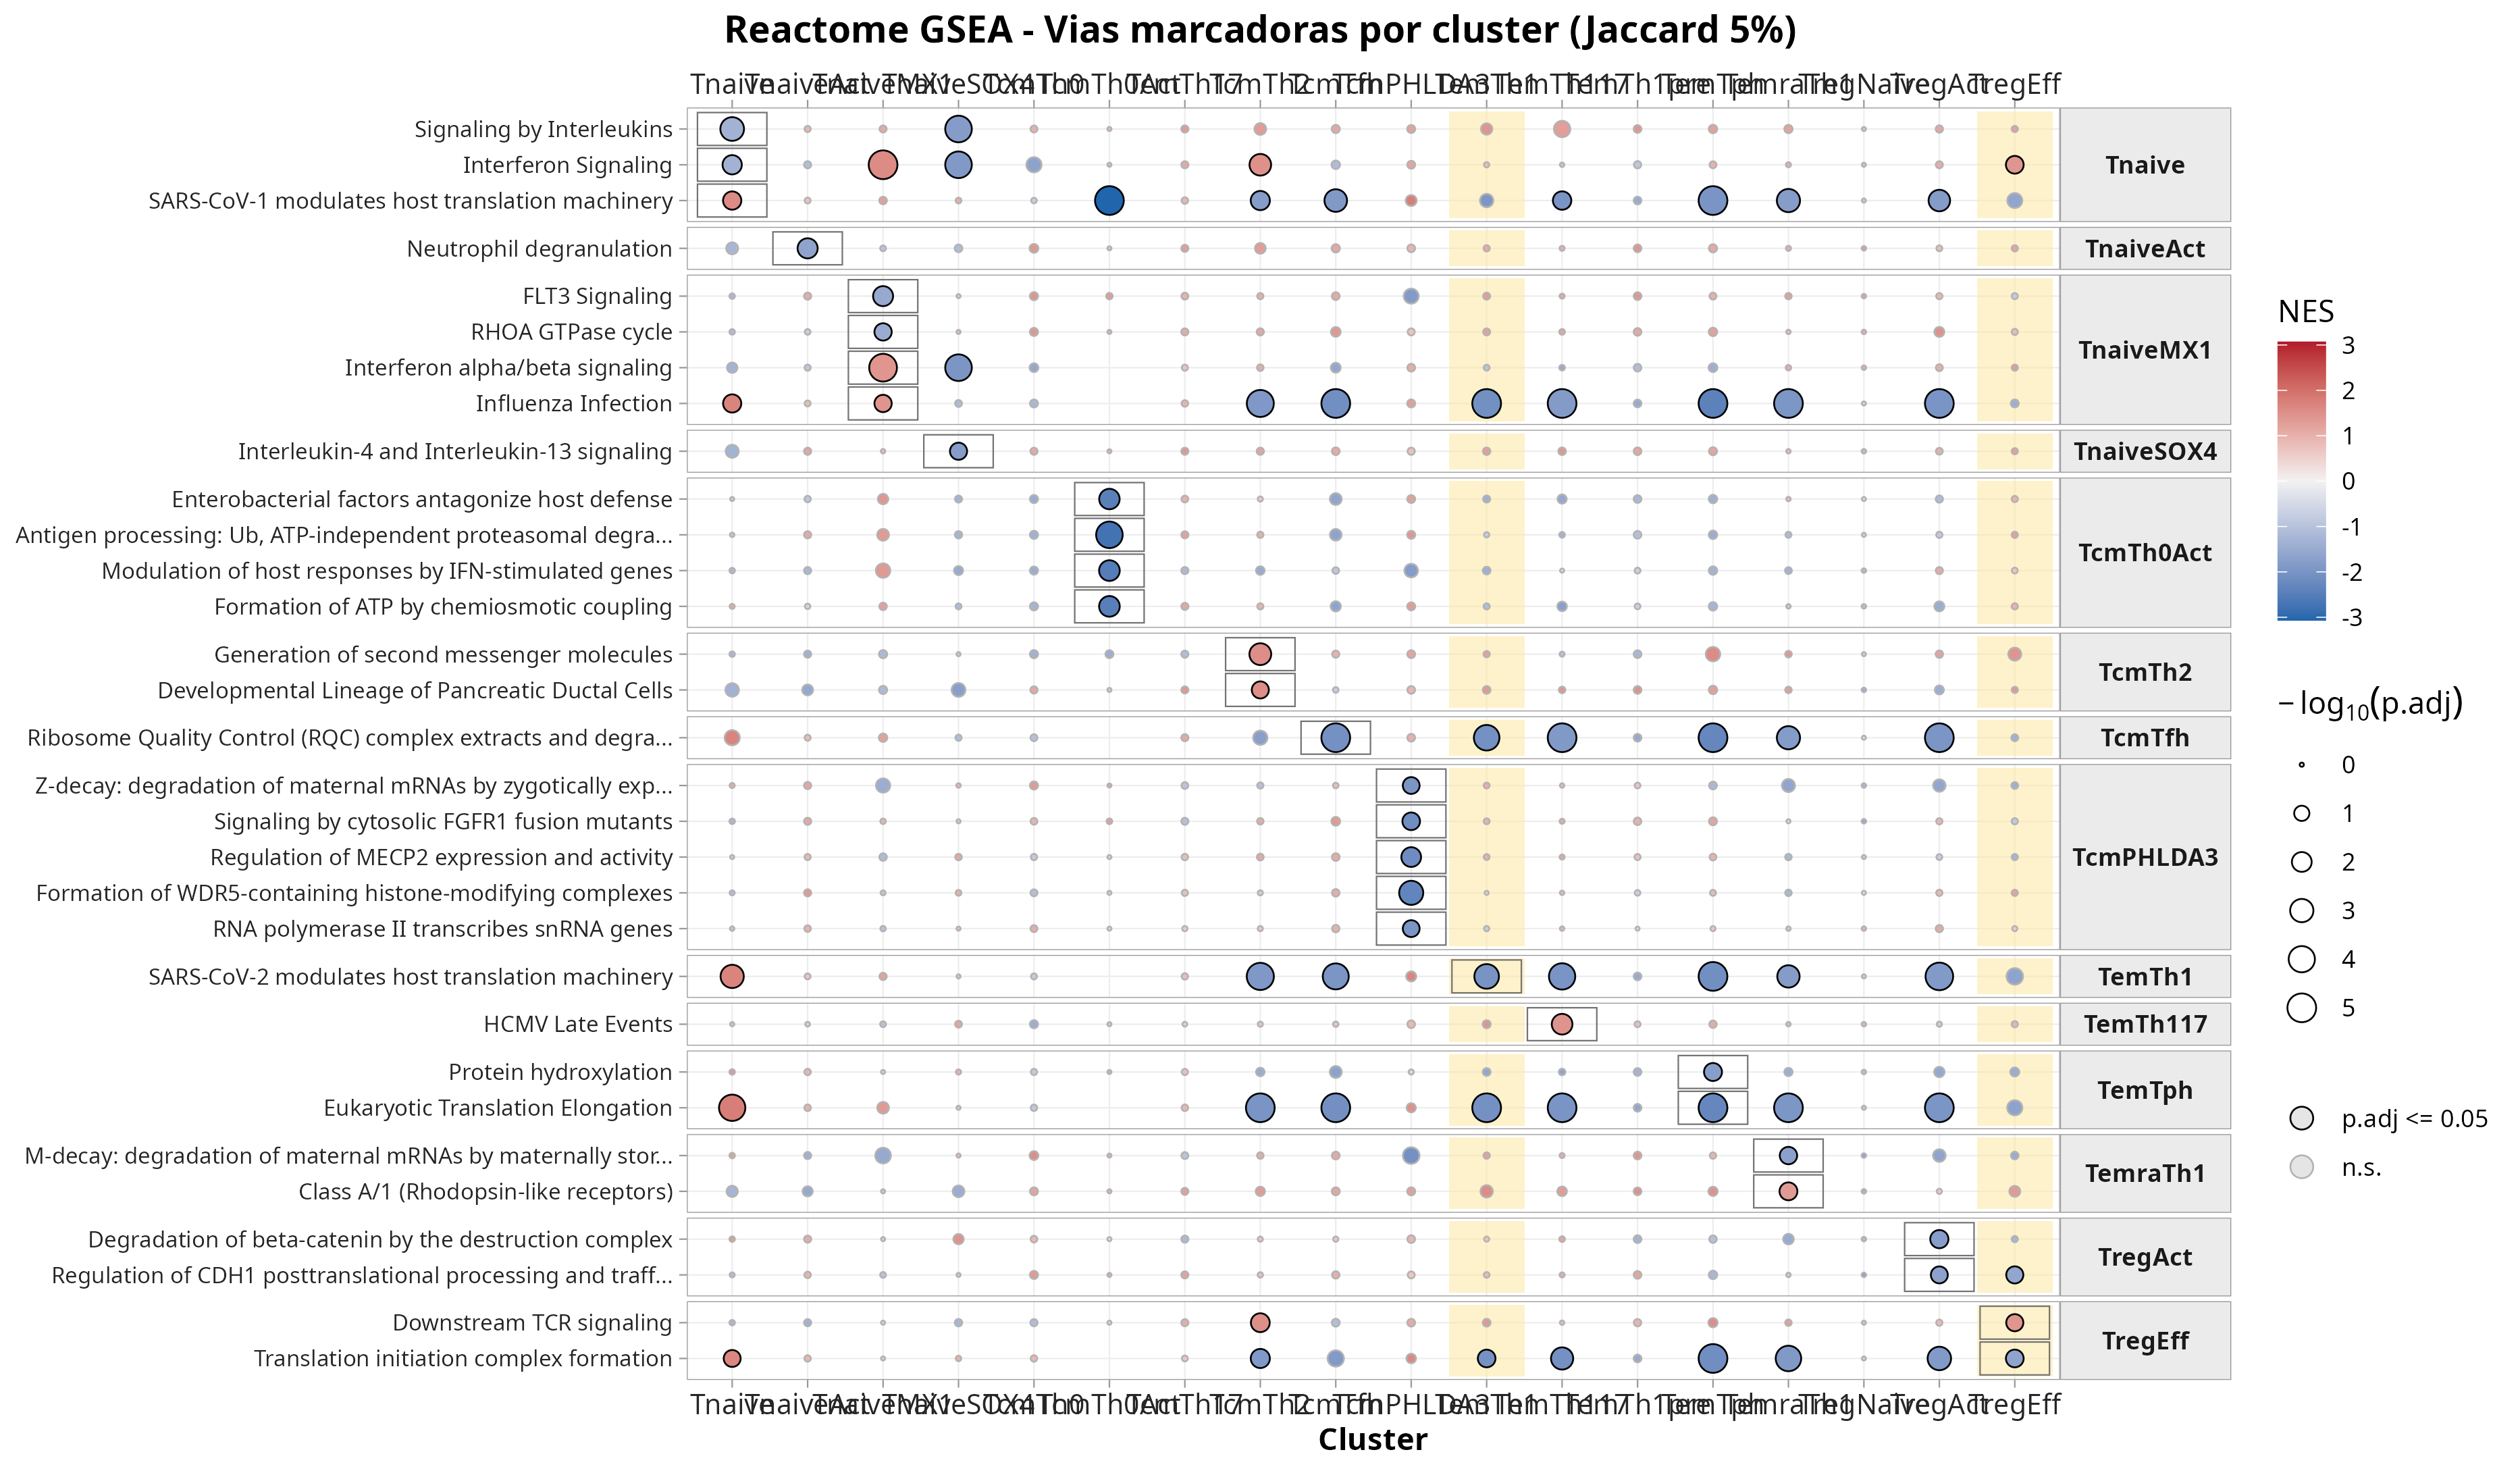

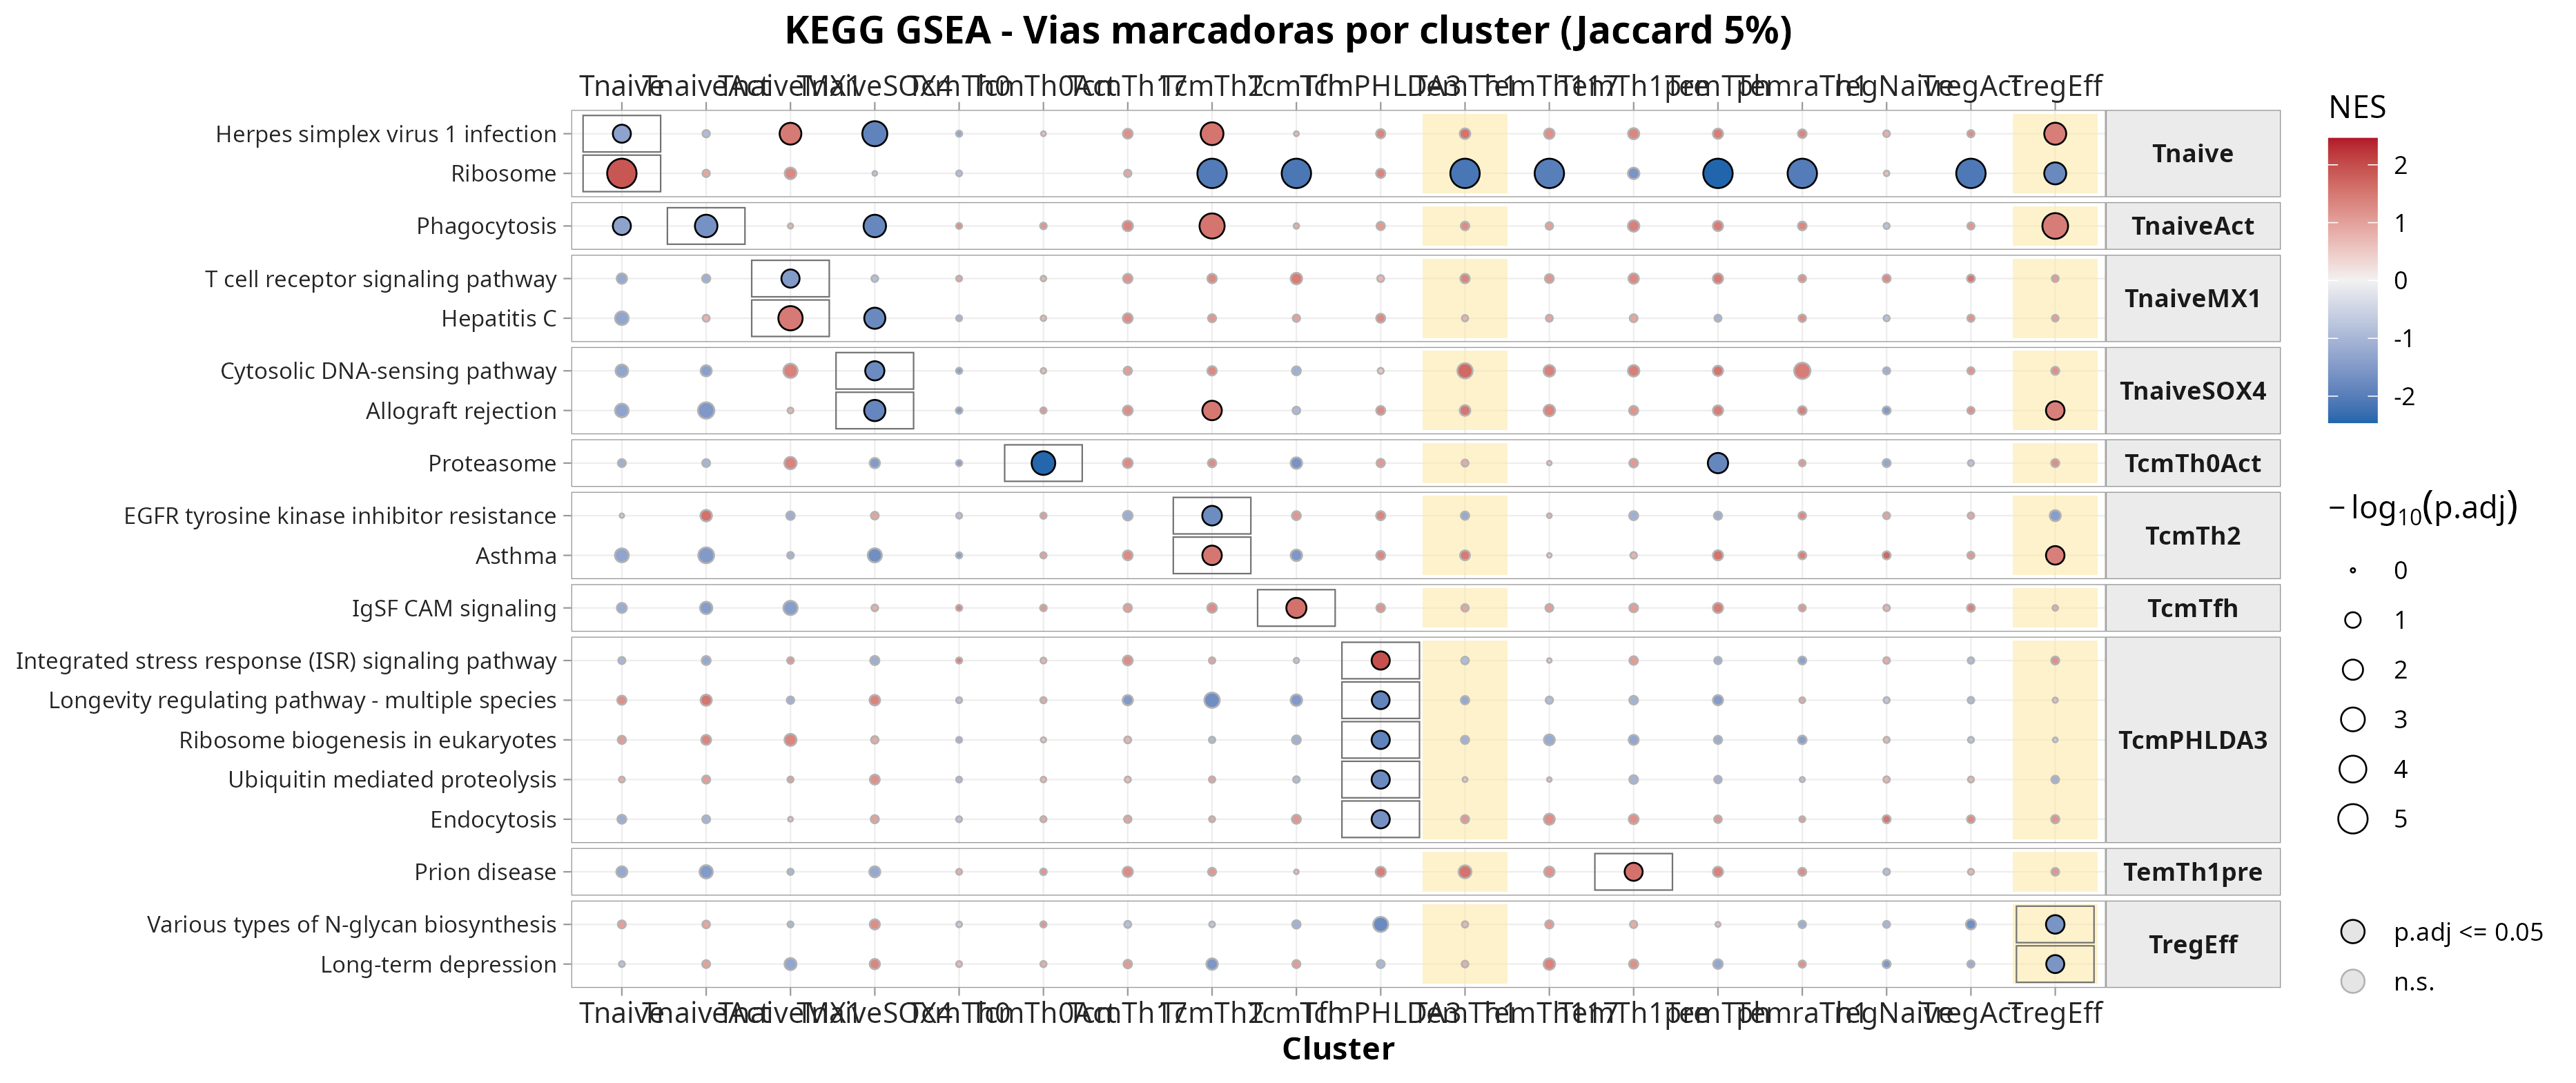

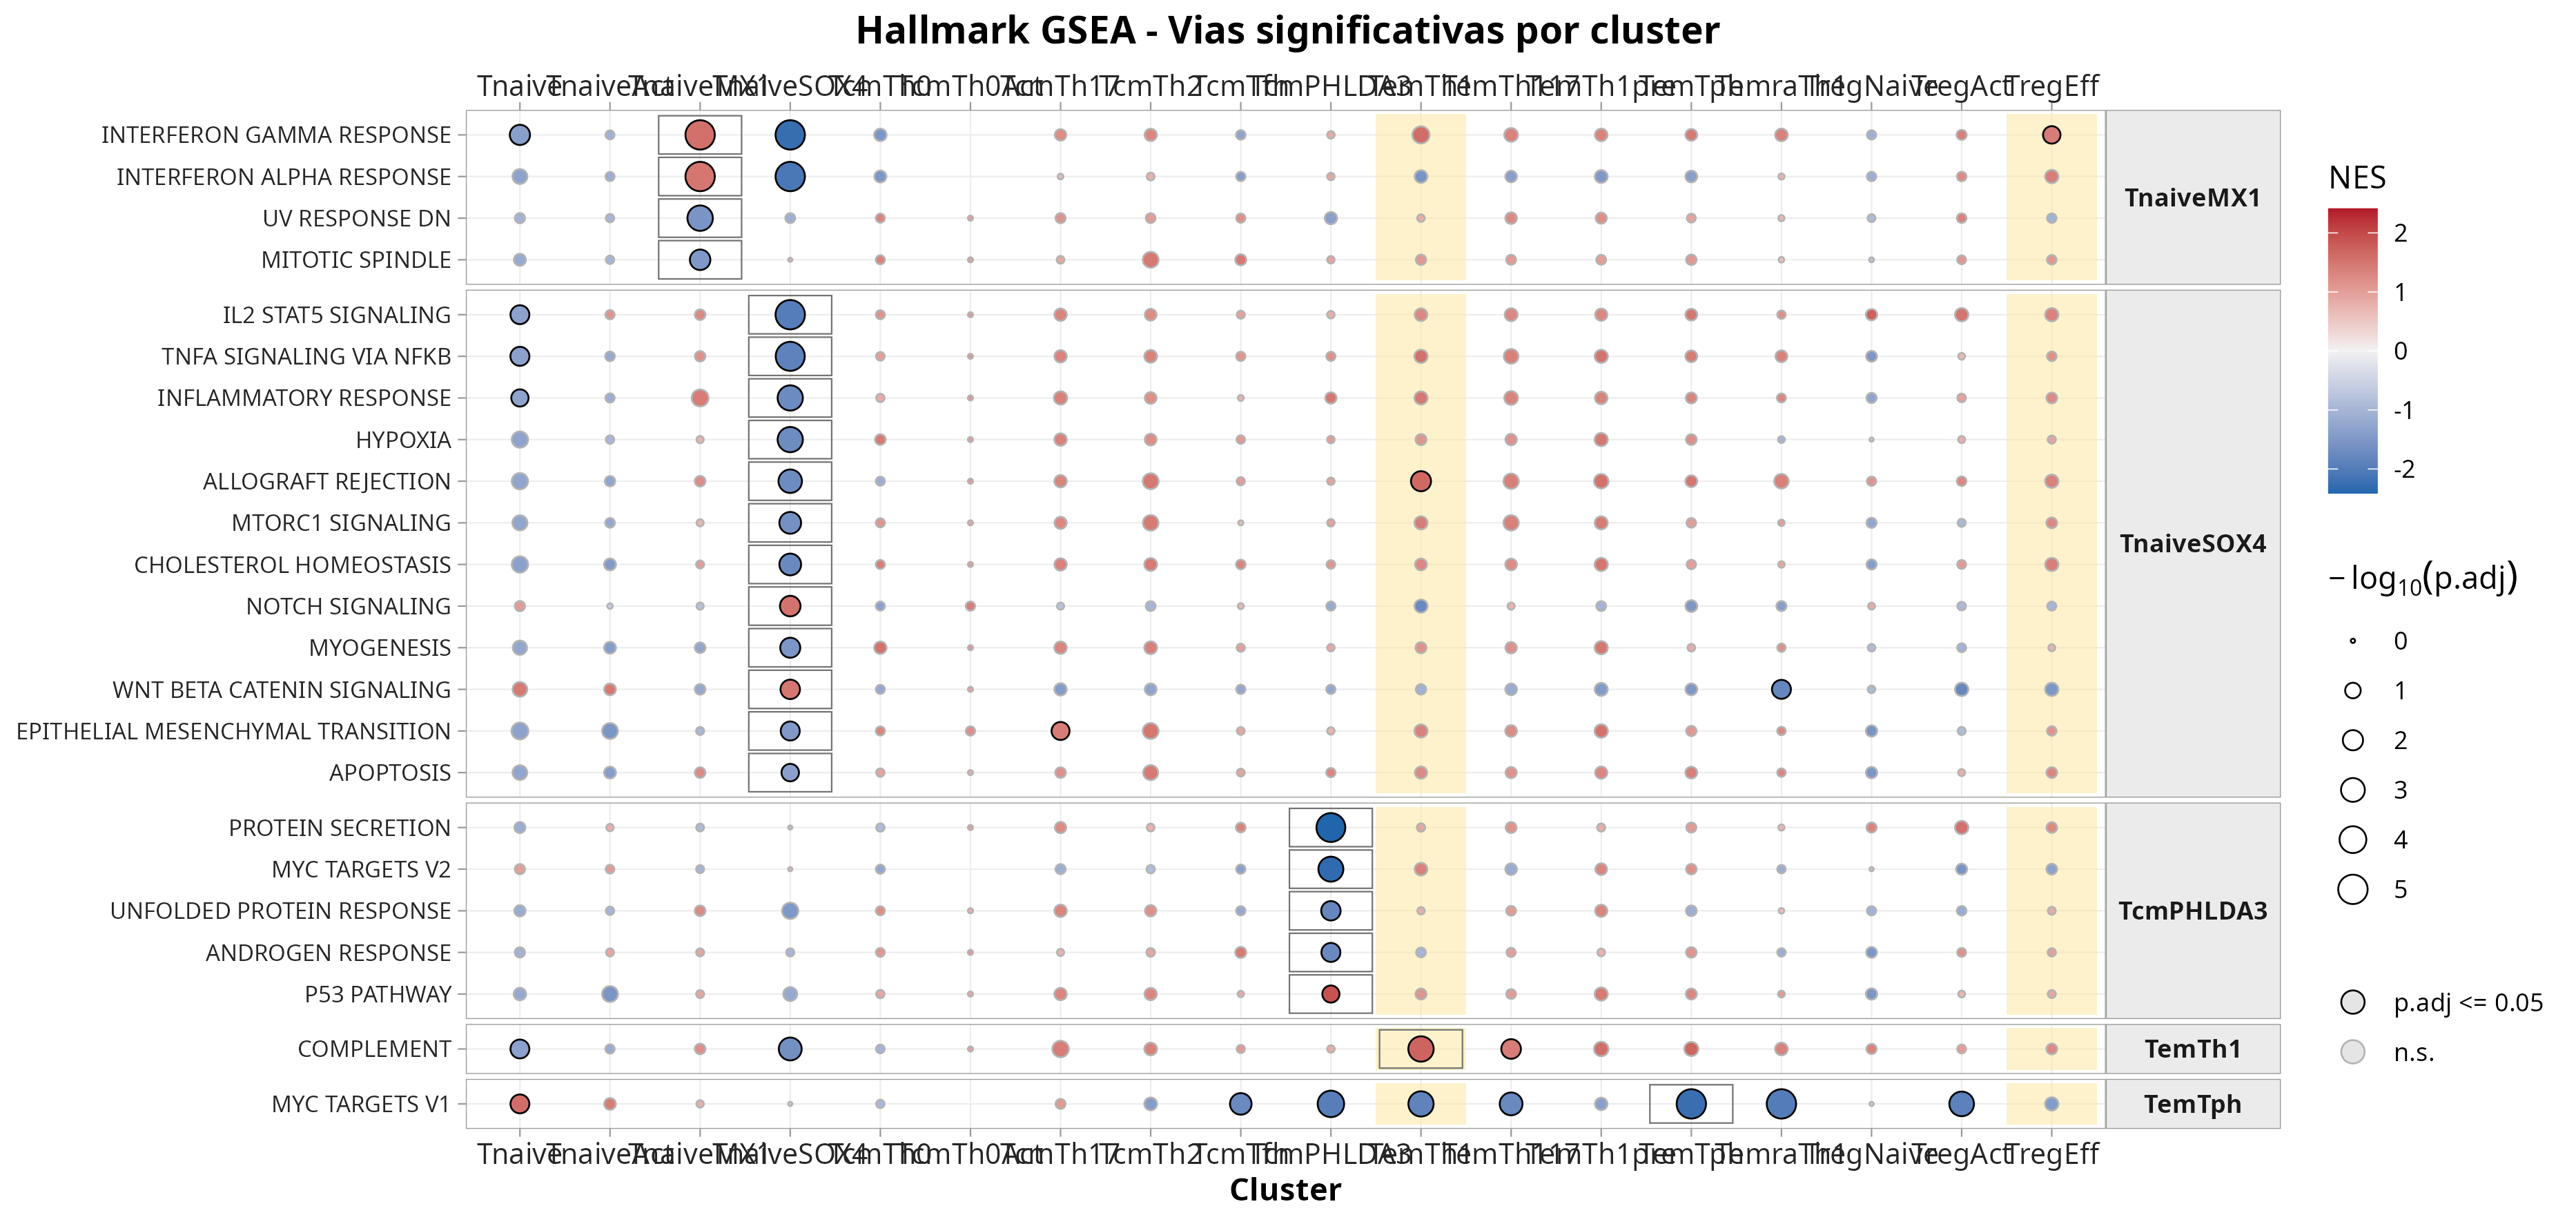

In [5]:
for b in ["reactome", "kegg", "hallmark"]:
    display(Image(filename=str(FIG / "L2" / f"gsea_{b}_marcadoras_combinado.png"), width=1100))

## 5. Treg × T efetora

O contraste principal (Teff estrita). Na coluna "Treg", NES > 0 = via mais alta na Treg do que na
Teff; a coluna "Teff" é o mesmo teste com o sinal trocado.

In [6]:
def contraste(nome):
    """Vias significativas no contraste Treg × Teff (lado da Treg), por base."""
    linhas = []
    for b, arq in BASES:
        d = pd.read_csv(TAB / nome / arq)
        t = d[(d["cluster"] == "Treg")][["ID", "Description", "setSize", "NES", "p.adjust"]].assign(base=b)
        linhas.append(t)
    return pd.concat(linhas, ignore_index=True)


ce = contraste("treg_teff_estrita")
lado = ce.rename(columns={"NES": "NES estrita", "p.adjust": "p.adjust estrita"})
for run, suf in [("treg_teff_ampla", "ampla"), ("treg_teff_estrita_sinal_log10p", "sinal×log10p"),
                 ("treg_teff_estrita_log2fc", "log2FC")]:
    lado = lado.merge(contraste(run)[["base", "ID", "NES", "p.adjust"]].rename(
        columns={"NES": f"NES {suf}", "p.adjust": f"p.adjust {suf}"}), on=["base", "ID"], how="outer")
io.save_table(lado, NB, "treg_vs_teff_sensibilidade", index=False,
              description="Lado Treg do contraste Treg × Teff: Teff estrita (score do espacial), ampla e dois scores alternativos")
n_sig = pd.DataFrame({c.replace("p.adjust ", ""): lado.groupby("base")[c].apply(lambda s: int((s <= 0.05).sum()))
                      for c in lado.columns if c.startswith("p.adjust")})
print("vias com p.adj ≤ 0,05 no lado Treg, por ranking:"); display(n_sig)
sig_e = lado[(lado[[c for c in lado.columns if c.startswith("p.adjust")]] <= 0.05).any(axis=1)]
cols_nes = [c for c in lado.columns if c.startswith("NES")]
for b in ["Hallmark", "KEGG", "Reactome"]:
    t = sig_e[sig_e["base"] == b].sort_values("NES sinal×log10p")
    conc = (np.sign(t[cols_nes]).nunique(axis=1) == 1).sum()
    print(f"\n== {b}: {len(t)} vias com p.adj ≤ 0,05 em algum ranking; mesmo sinal nos quatro: {conc}")
    with pd.option_context("display.max_colwidth", 60, "display.width", 250):
        display(pd.concat([t.head(12), t.tail(12)]).drop_duplicates()[["Description", "setSize"] + [
            c for c in lado.columns if c.startswith(("NES", "p.adjust"))]].round(3))

vias com p.adj ≤ 0,05 no lado Treg, por ranking:


,estrita,ampla,sinal×log10p,log2FC
base,,,,
Hallmark,0,0,3,13
KEGG,0,0,0,20
Reactome,0,1,3,102



== Hallmark: 13 vias com p.adj ≤ 0,05 em algum ranking; mesmo sinal nos quatro: 8


,Description,setSize,NES estrita,p.adjust estrita,NES ampla,p.adjust ampla,NES sinal×log10p,p.adjust sinal×log10p,NES log2FC,p.adjust log2FC
9,COAGULATION,110,-1.461,0.584,-1.527,0.607,-1.728,0.022,-1.530,0.031
13,EPITHELIAL MESENCHYMAL TRANSITION,166,-1.193,0.584,-1.053,0.734,-1.419,0.290,-1.820,0.000
33,MYOGENESIS,165,-1.376,0.584,-1.350,0.734,-1.333,0.361,-1.511,0.010
44,TNFA SIGNALING VIA NFKB,196,-1.298,0.584,-0.904,0.858,-1.320,0.337,-1.659,0.001
28,KRAS SIGNALING UP,177,-1.162,0.649,-0.976,0.759,-1.254,0.426,-1.681,0.001
10,COMPLEMENT,187,-1.277,0.584,0.736,0.914,-1.188,0.470,-1.619,0.001
18,GLYCOLYSIS,187,-0.930,0.810,0.690,0.942,-0.963,0.713,-1.427,0.013
24,INFLAMMATORY RESPONSE,187,-1.054,0.745,0.870,0.891,0.996,0.713,-1.529,0.003
12,E2F TARGETS,199,-0.844,0.822,1.130,0.734,1.075,0.616,1.602,0.003
1,ALLOGRAFT REJECTION,188,-0.867,0.815,1.209,0.734,1.157,0.508,-1.590,0.002



== KEGG: 20 vias com p.adj ≤ 0,05 em algum ranking; mesmo sinal nos quatro: 15


,Description,setSize,NES estrita,p.adjust estrita,NES ampla,p.adjust ampla,NES sinal×log10p,p.adjust sinal×log10p,NES log2FC,p.adjust log2FC
162,ErbB signaling pathway,84,-1.359,0.591,-1.305,0.833,-1.513,0.221,-1.661,0.016
176,Phospholipase D signaling pathway,138,-1.302,0.595,-1.089,0.885,-1.451,0.254,-1.526,0.042
342,Malaria,43,-1.243,0.764,-1.106,0.885,-1.414,0.454,-1.831,0.014
340,Chagas disease,96,-1.443,0.550,-1.162,0.885,-1.362,0.454,-1.913,0.001
242,IL-17 signaling pathway,77,-1.198,0.773,-0.977,0.910,-1.229,0.565,-1.887,0.004
170,Chemokine signaling pathway,169,-1.209,0.734,0.936,0.936,-1.180,0.564,-1.758,0.003
329,Alcoholism,158,0.752,0.971,0.932,0.936,0.792,0.924,1.608,0.009
241,Natural killer cell mediated cytotoxicity,103,-0.745,0.971,1.200,0.885,0.961,0.803,-1.837,0.004
237,Cytosolic DNA-sensing pathway,67,-1.145,0.806,0.915,0.936,1.043,0.741,-1.763,0.014
169,Viral protein interaction with cytokine and cytokine rec...,78,-0.786,0.970,1.187,0.885,1.150,0.630,-1.834,0.004



== Reactome: 102 vias com p.adj ≤ 0,05 em algum ranking; mesmo sinal nos quatro: 86


,Description,setSize,NES estrita,p.adjust estrita,NES ampla,p.adjust ampla,NES sinal×log10p,p.adjust sinal×log10p,NES log2FC,p.adjust log2FC
452,Signaling by ERBB2,49,-1.427,0.929,-1.452,0.923,-1.585,0.746,-1.814,0.014
1046,Axon guidance,500,-1.409,0.929,-1.311,0.923,-1.530,0.235,-1.350,0.034
585,Complement cascade,39,-1.380,0.929,-1.424,0.923,-1.510,0.774,-1.735,0.027
1537,Downregulation of ERBB2 signaling,29,-1.431,0.929,-1.417,0.923,-1.472,0.774,-1.869,0.014
1879,Regulation of Complement cascade,33,-1.359,0.929,-1.417,0.923,-1.449,0.774,-1.722,0.041
1034,G alpha (i) signalling events,230,-1.306,0.929,-0.845,0.978,-1.419,0.774,-1.499,0.018
931,Class A/1 (Rhodopsin-like receptors),210,-1.186,0.929,0.786,0.988,-1.362,0.774,-1.517,0.018
969,GPCR downstream signalling,469,-1.185,0.929,0.867,0.978,-1.358,0.760,-1.545,0.002
1131,GPCR ligand binding,302,-1.185,0.929,0.772,0.988,-1.334,0.774,-1.493,0.010
947,Chemokine receptors bind chemokines,46,-1.216,0.929,0.793,0.978,-1.278,0.775,-1.770,0.030


In [7]:
for b in ["hallmark", "kegg", "reactome"]:
    p = FIG / "treg_teff_estrita" / f"gsea_{b}_comparacao_Treg_vs_Teff.png"
    if p.exists():
        display(Image(filename=str(p), width=850))

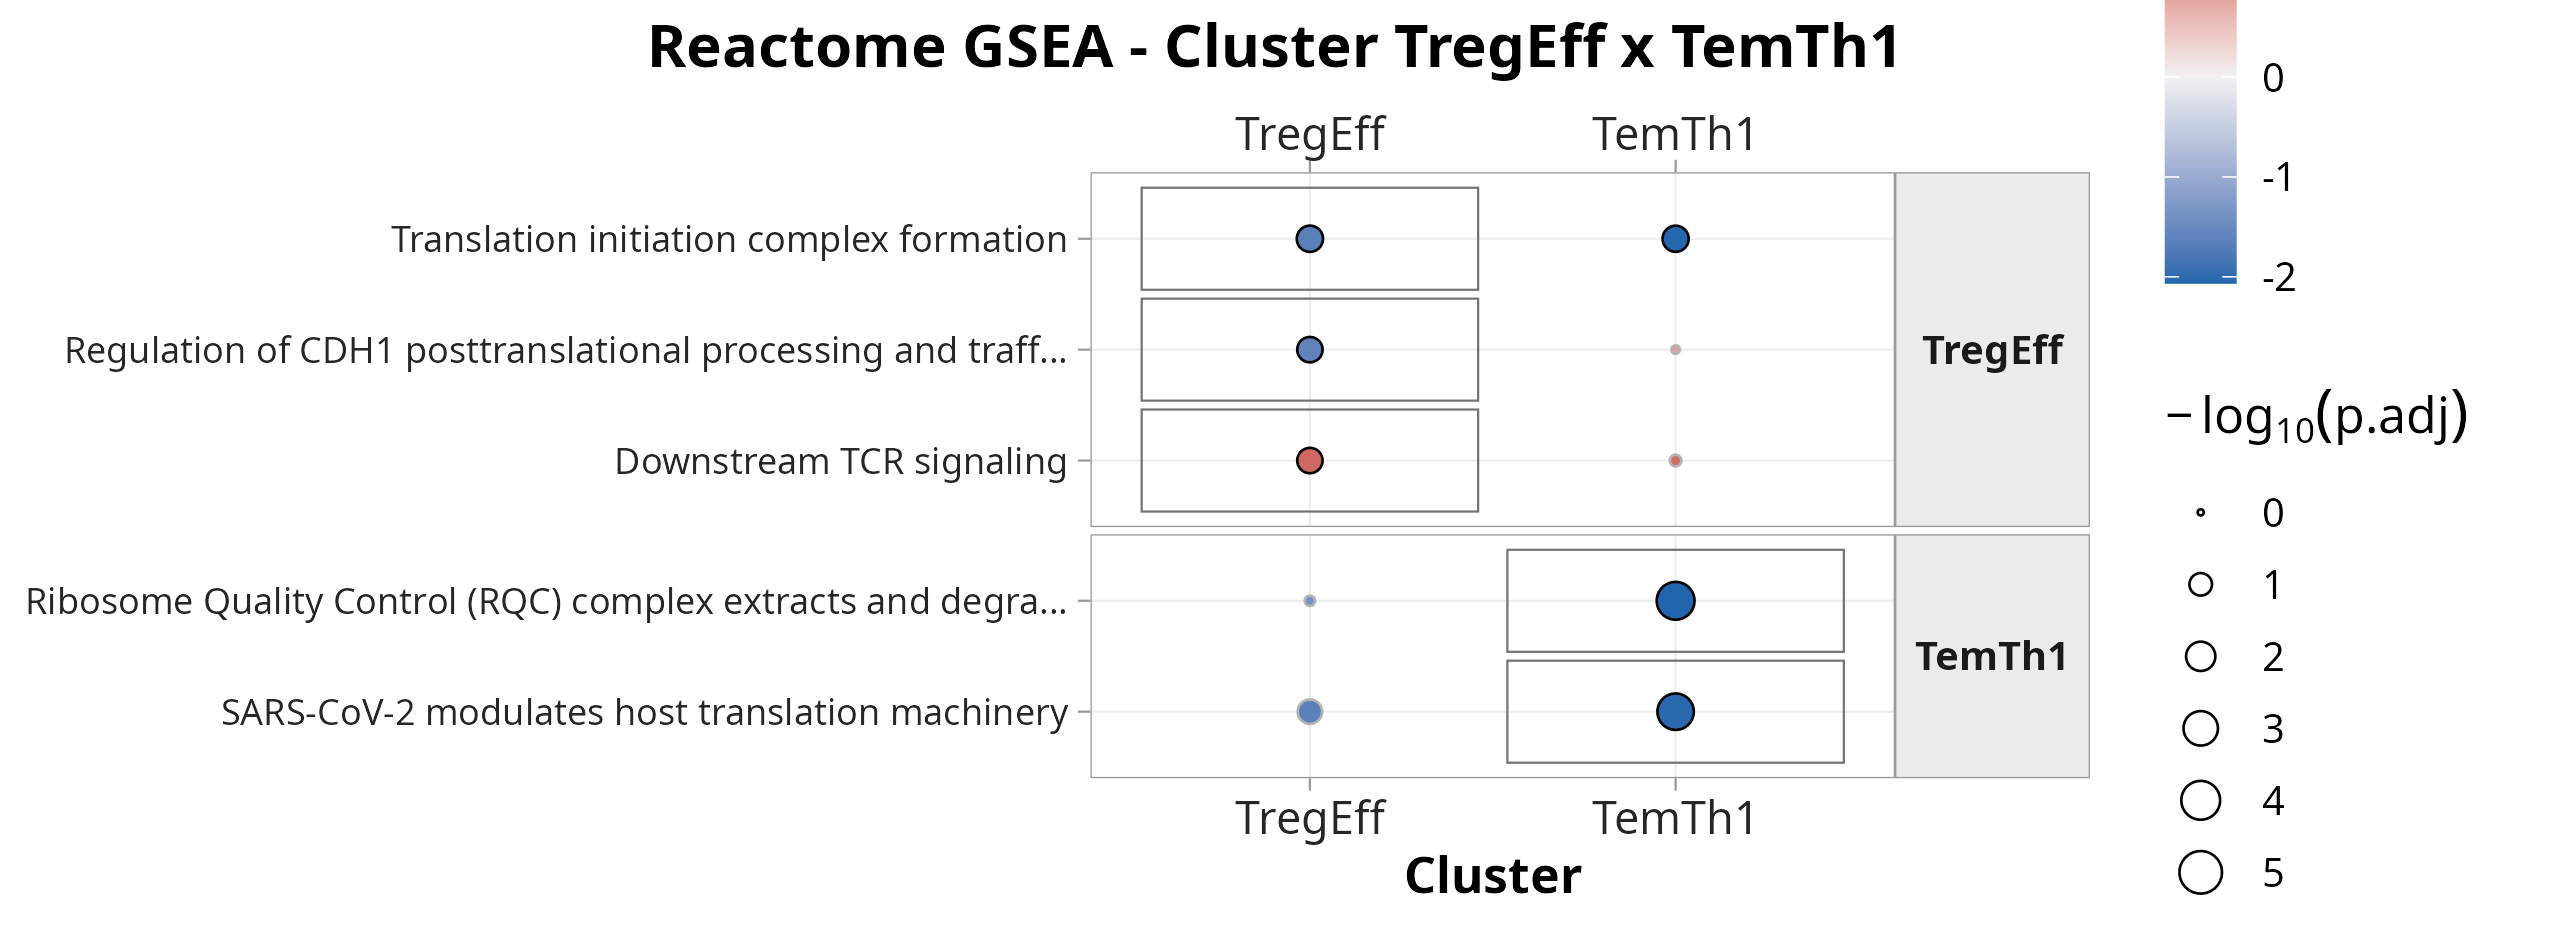

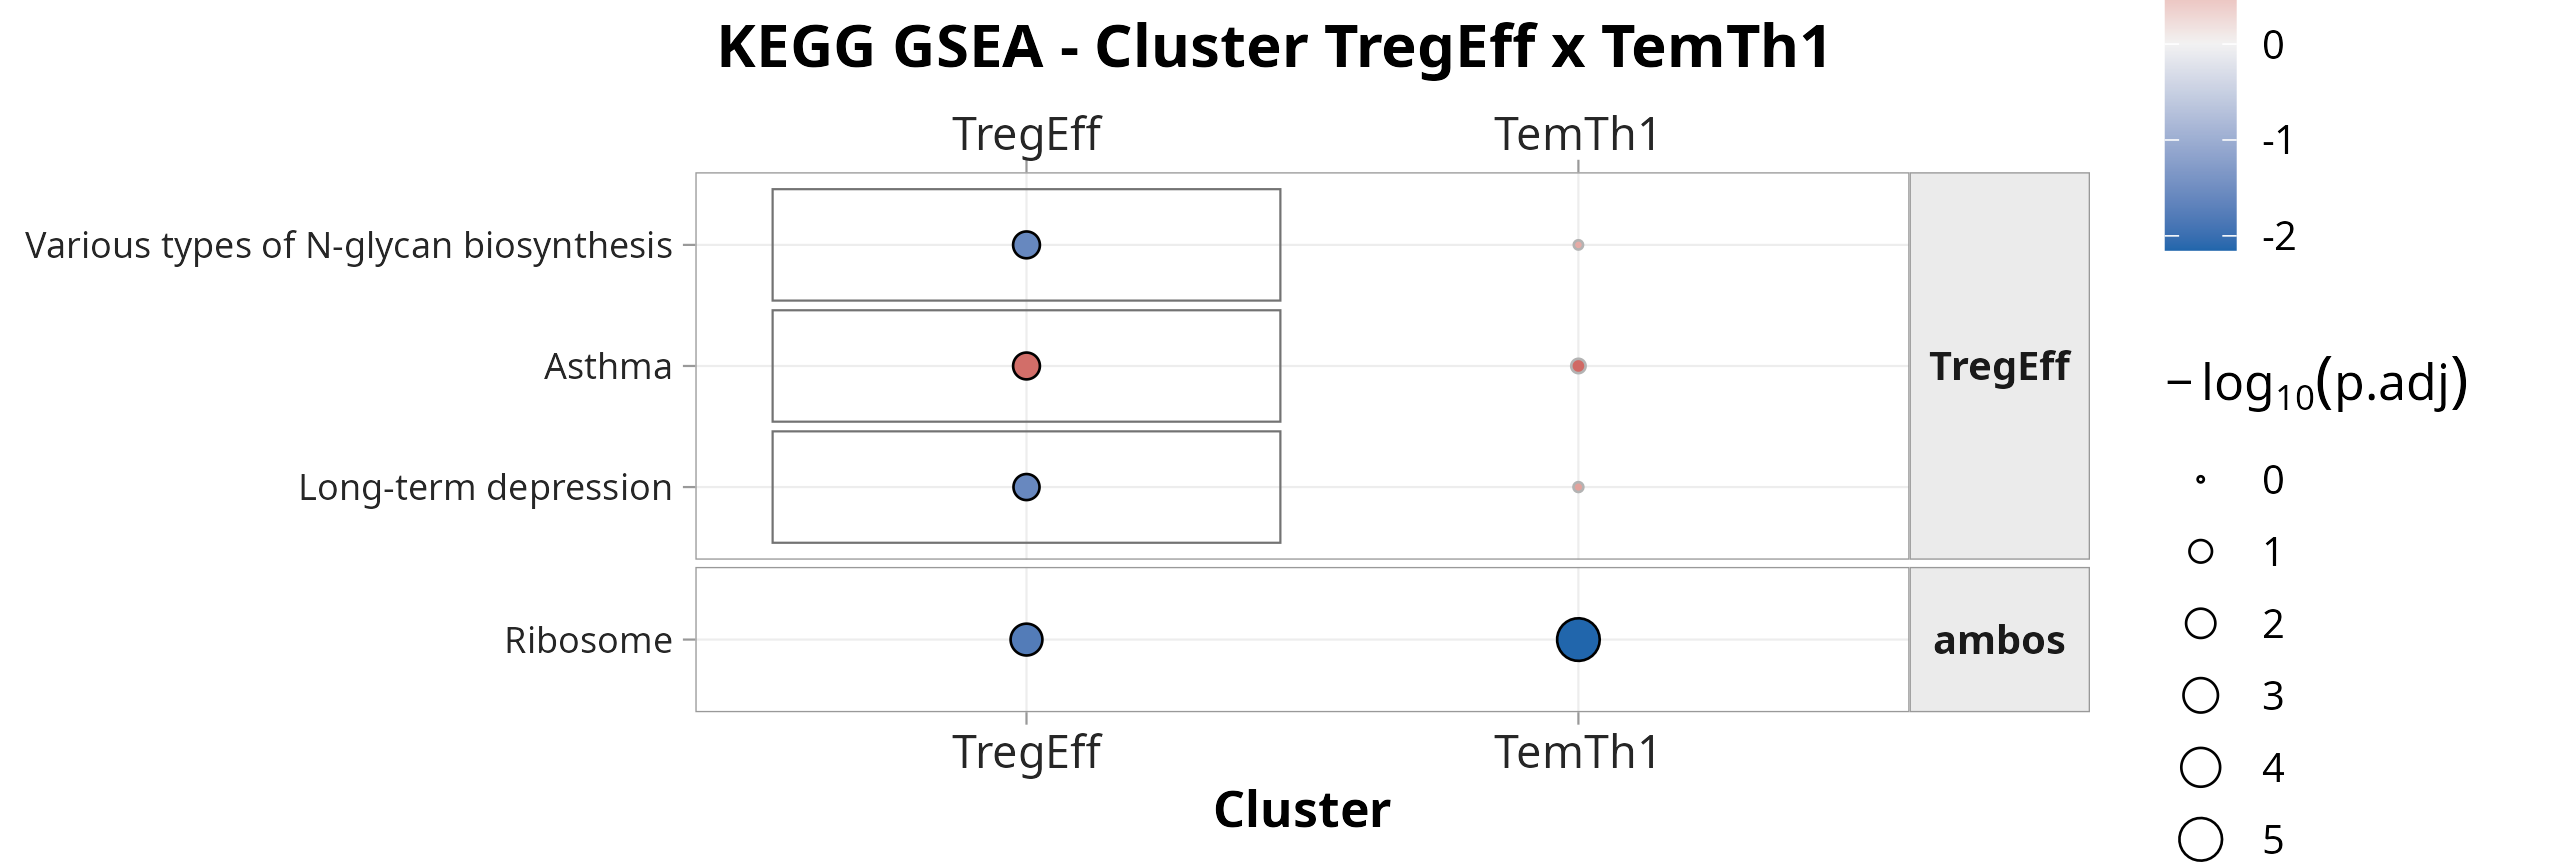

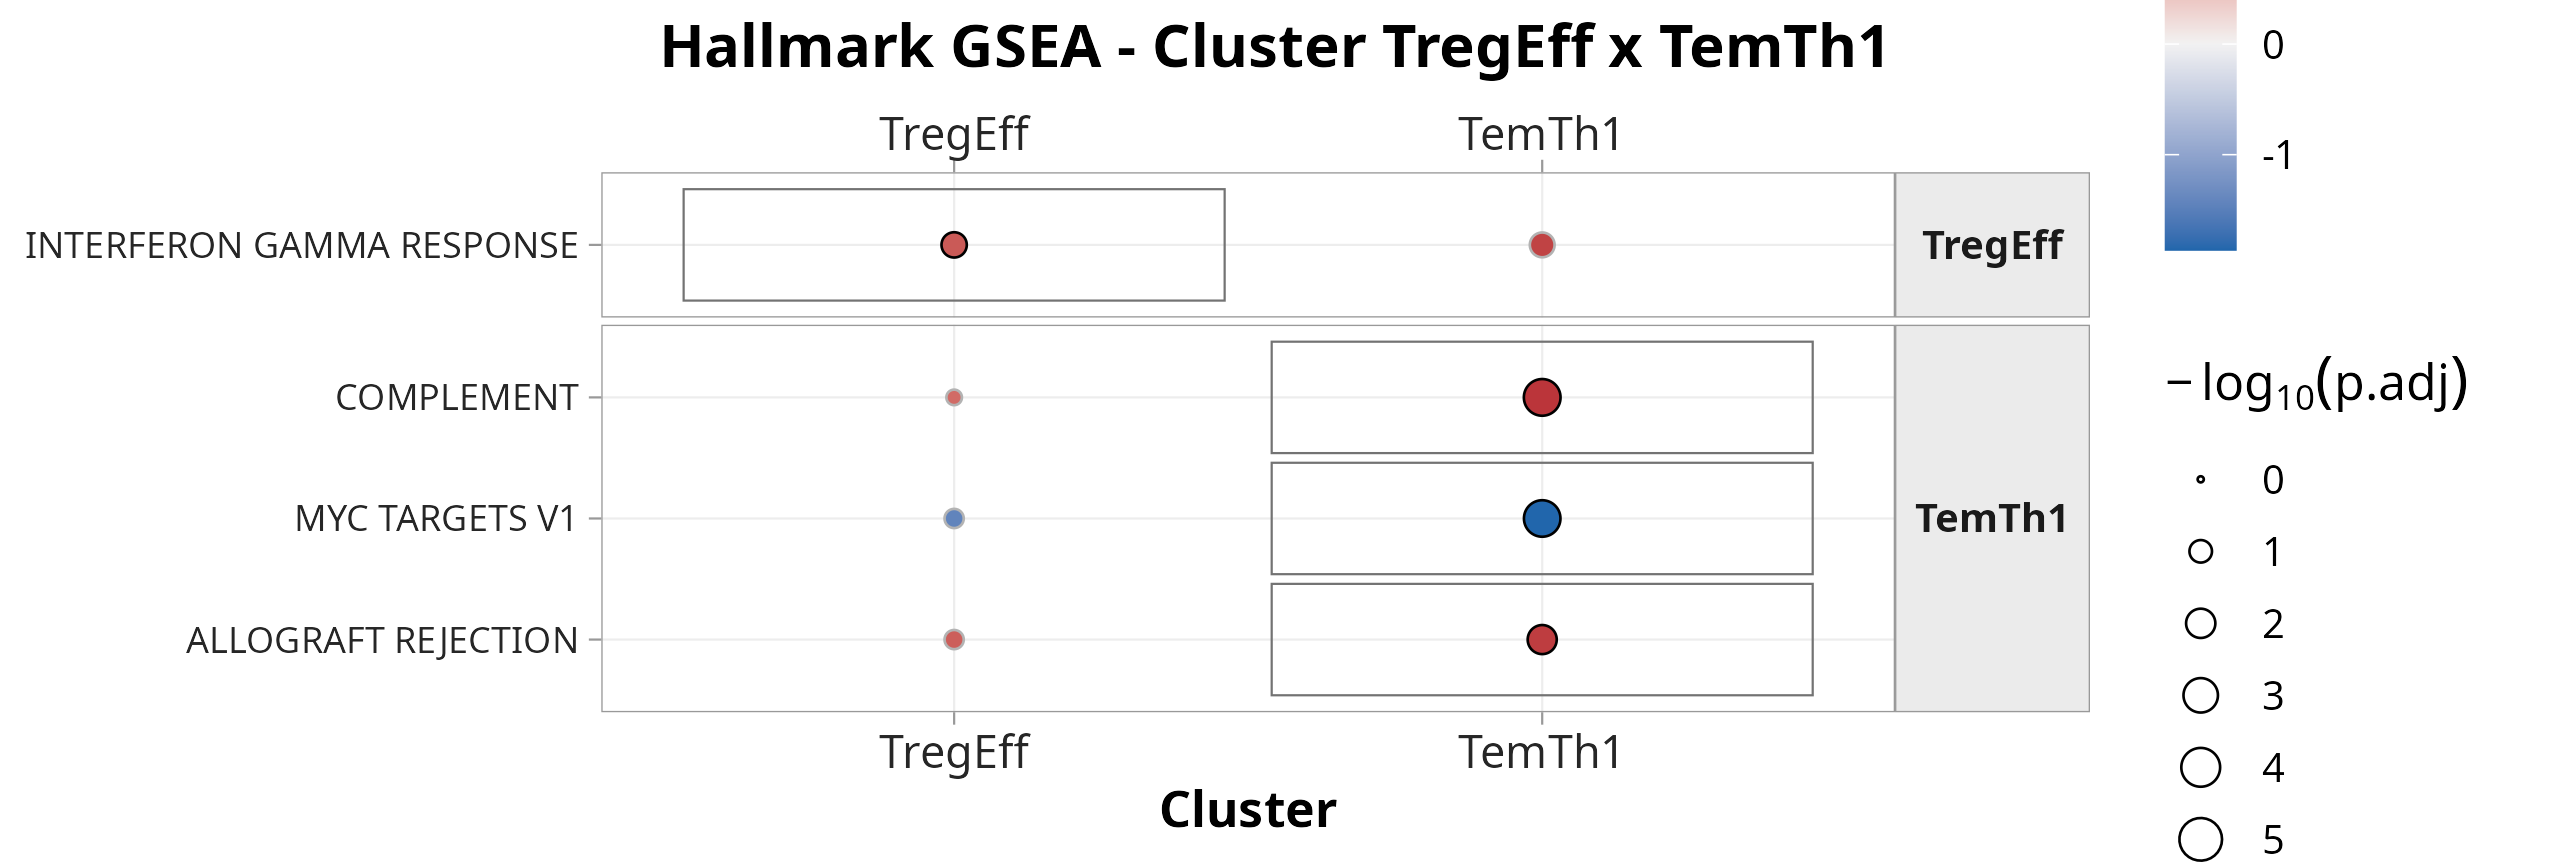

In [8]:
for b in ["reactome", "kegg", "hallmark"]:
    p = FIG / "L2" / f"gsea_{b}_comparacao_TregEff_vs_TemTh1.png"
    if p.exists():
        display(Image(filename=str(p), width=850))

## 6. Interpretação

**O score do espacial perde poder com o ranking completo.** Mesmo com o p bruto, o
`−log10(p)` vai a ~300 nos genes mais fortes (p = 0 recebe o piso de ~1e-318) contra mediana
~0,2: o GSEA fica dominado por poucas dezenas de genes. Por isso o Hallmark e o KEGG dão poucas
vias por tipo L2, e o contraste Treg × Teff não tem nenhuma via com p.adj ≤ 0,05 no score do
espacial (estrita e ampla). A **ordem das vias**, porém, é a mesma nos quatro rankings: o sinal
do NES concorda em 86 de 102 vias do Reactome, 15 de 20 do KEGG e 8 de 13 do Hallmark. Com
`sinal × −log10(p)` passam 3 hallmarks e 3 Reactome; só com o log2FC, 13, 20 e 102.

**Treg × T efetora (o contraste principal).** Mais alto na Treg do que na Teff, nos quatro
rankings:

* **interferon tipo I e II** (Hallmark IFN-α NES 1,5 a 2,0, p.adj < 0,001 em dois rankings;
  Reactome "Interferon Signaling" p.adj 0,025 já com a Teff ampla e o score do espacial);
* **sinalização do TCR** (fosforilação de CD3/ζ, ZAP-70, segundo mensageiro) e **apresentação
  por MHC classe II** (HLA-DR nas Treg efetoras), **coinibição por PD-1**;
* ciclo celular (E2F, G2M), coerente com a proliferação da Treg ativada.

Mais alto na Teff: **TNF-α via NF-κB**, resposta inflamatória, complemento, IL-17, quimiocinas e
receptores de quimiocina, sinalização por GPCR e citotoxicidade NK — o programa efetor e de
migração. Na marcação dos genes, o topo da Treg é FOXP3, IKZF2 (Helios), RTKN2, TIGIT e IL2RA, e
o fundo, IL7R: as Treg do atlas, nesse contraste com as Teff, são Treg de verdade em média, apesar
da contaminação por ativadas em ML vista no P14.

**Os 18 tipos L2.** O Reactome separa os tipos (1 a 45 vias por tipo); TregEff tem MHC II,
glicosilação e as vias KEGG de apresentação de antígeno (29 vias KEGG, a maior contagem);
as T de memória efetora (TemTh1, TemTph, TemraTh1, TemTh117) e a TcmTfh têm MYC targets e
tradução/rRNA para baixo. TcmPHLDA3 (17 células) e TcmTh0Act (29) não devem ser lidos.

**Limites.** É um GSEA de marcadores no nível da célula, com todas as bibliotecas juntas
(NS e ML): descreve o que distingue os tipos, não o efeito do estímulo nem dos grupos clínicos.

## Problemas encontrados

In [9]:
pequenos = tam["L2"][tam["L2"] < 50]
log.add("MINOR", "seção 1", "clusters L2 com poucas células no GSEA",
        evidence="; ".join(f"{k}: {v} células" for k, v in pequenos.items()) or "nenhum",
        impact="ranking ruidoso; as vias desses clusters são frágeis",
        recommendation="não interpretar vias de clusters com < 50 células sem confirmação")
log.add("INFO", "seção 2", "parâmetros do FindAllMarkers do espacial desconhecidos",
        evidence="usado o ranking completo, sem cortes (logfc.threshold = 0, min.pct = 0, return.thresh = Inf)",
        impact="NES e vias podem diferir do que o espacial teria dado com os parâmetros dele",
        recommendation="se os parâmetros do espacial aparecerem, rodar de novo com eles para comparar")
df_issues = log.save()
issues.show(df_issues)

severity,location,problem,evidence,impact,recommendation
MINOR,seção 1,clusters L2 com poucas células no GSEA,TcmPHLDA3: 17.0 células; TcmTh0Act: 29.0 células,ranking ruidoso; as vias desses clusters são frágeis,não interpretar vias de clusters com < 50 células sem confirmação
INFO,seção 2,parâmetros do FindAllMarkers do espacial desconhecidos,"usado o ranking completo, sem cortes (logfc.threshold = 0, min.pct = 0, return.thresh = Inf)",NES e vias podem diferir do que o espacial teria dado com os parâmetros dele,"se os parâmetros do espacial aparecerem, rodar de novo com eles para comparar"
